# Notebook 03 — Décision, coûts et ROI
**Projet final · S7MOI1 · Science des Données, concepts avancés · ECAM-EPMI · 2AE**
Équipe : AKONDE Esly · DELBARD-MAZZOLA Paul-Baptiste · DIOP Abdou Aziz

## Point de départ
Résultats du notebook 02 utilisés ici (test 2010, 305 jours, utilisé une seule fois) : MAE du Random Forest réglé de 4,22 kWh/jour contre 5,10 pour la baseline « comme hier », soit 17,2 % de gain ; intervalle d'erreur à 90 % de −10,3 à +10,6 kWh ; les journées atypiques sont environ deux fois plus mal prévues (MAE de 10,26 contre 5,03 kWh/jour).

## Objectif
Traduire l'erreur de prévision en **euros** (axe 6), calculer le **ROI** avec scénarios et analyse de sensibilité (axe 7), établir le **registre de risques** (axe 9) et formuler une **recommandation** au décideur.

## Cadrage de la valeur : un parc de foyers
Le foyer de la base UCI est un cas d'étude. La décision métier (acheter l'énergie de demain) est prise par un fournisseur pour un **parc de N foyers**. Pour estimer la valeur, nous supposons que le foyer étudié est représentatif d'un foyer du parc : c'est l'hypothèse centrale du projet, à valider par un pilote.

Un second paramètre conditionne tout le calcul, le **foisonnement** τ : sur un parc, les erreurs individuelles se compensent en partie (un foyer consomme trop, un autre pas assez). Nous définissons τ comme la part de l'effet mesuré sur un foyer qui subsiste sur le parc agrégé : τ = 1 si tous les foyers se trompent dans le même sens au même moment, et τ proche de 0 si leurs erreurs se compensent presque entièrement. Ce paramètre ne peut pas être mesuré avec les données d'un seul foyer ; il est donc posé comme hypothèse critique, calibré par un ordre de grandeur (section 4) et soumis à l'analyse de sensibilité.

## Plan
0. Mise en place · 1. Hypothèses de coûts · 2. Coût des erreurs de prévision · 3. Marge de sécurité · 4. ROI, scénarios et sensibilité · 5. Registre de risques · 6. Recommandation

## 0 · Mise en place et chargement
Ce notebook utilise deux fichiers produits par les notebooks précédents : `features_journalieres.csv` (notebook 01) et `predictions_test.csv` (notebook 02). Si la session Colab a été réinitialisée, relancer les notebooks 01 et 02, ou importer ces deux fichiers lorsque la cellule le demande.

Pour choisir la marge de sécurité (section 3) **sans toucher au jeu de test**, nous recalculons les prévisions de validation du notebook 02 avec exactement la configuration retenue (Random Forest, `max_depth = 12`, `min_samples_leaf = 10`, validation temporelle à 5 plis).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (10, 4)

DATA_DIR = "data"
FICHIERS = ["features_journalieres.csv", "predictions_test.csv"]

# Les CSV sont lus localement s'ils existent. Sinon, on les télécharge depuis le dossier data/ du dépôt GitHub.
os.makedirs(DATA_DIR, exist_ok=True)
BASE_CSV_URL = "https://raw.githubusercontent.com/akondeesly-cyber/prevision-conso-electrique/main/data/"
for nom in FICHIERS:
    chemin = os.path.join(DATA_DIR, nom)
    if not os.path.exists(chemin):
        url = BASE_CSV_URL + nom
        try:
            print(f"Téléchargement de {nom} depuis GitHub...")
            pd.read_csv(url, nrows=1)  # vérifie que le fichier est accessible
            import urllib.request
            urllib.request.urlretrieve(url, chemin)
        except Exception as e:
            raise FileNotFoundError(
                f"Impossible de récupérer {nom} depuis {url}. "
                "Vérifiez que le CSV a été ajouté au dossier data/ du dépôt GitHub. "
                "En local, exécutez d'abord le notebook précédent."
            ) from e

manquants = [f for f in FICHIERS if not os.path.exists(os.path.join(DATA_DIR, f))]
if manquants:
    raise FileNotFoundError(f"Fichiers CSV manquants : {manquants}")

feat = pd.read_csv(os.path.join(DATA_DIR, "features_journalieres.csv"), index_col="date", parse_dates=True)
pred = pd.read_csv(os.path.join(DATA_DIR, "predictions_test.csv"), index_col="date", parse_dates=True)
print("features_journalieres :", feat.shape, "| predictions_test :", pred.shape)

Téléchargement de features_journalieres.csv depuis GitHub...
Téléchargement de predictions_test.csv depuis GitHub...
features_journalieres : (1442, 7) | predictions_test : (305, 4)


In [2]:
FEATURES = ["lag_1", "lag_7", "mm7", "est_weekend", "jour_semaine", "mois"]
CIBLE = "conso_kwh"
NUM, CAT, BIN = ["lag_1", "lag_7", "mm7"], ["jour_semaine", "mois"], ["est_weekend"]

dispo = feat.dropna(subset=[CIBLE] + FEATURES)
DATE_COUPURE = pd.Timestamp("2010-01-01")
train = dispo.loc[dispo.index < DATE_COUPURE]
test = dispo.loc[dispo.index >= DATE_COUPURE]
X_train, y_train = train[FEATURES], train[CIBLE]
assert test.index.equals(pred.index), "predictions_test.csv ne correspond pas au jeu de test du notebook 02"

def faire_preprocess():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("bin", "passthrough", BIN),
    ])

modele = Pipeline([("prep", faire_preprocess()),
                   ("rf", RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=10,
                                                random_state=SEED, n_jobs=-1))])

# Prévisions hors échantillon (validation temporelle) : uniquement des jours de validation
tscv = TimeSeriesSplit(n_splits=5)
oof = pd.Series(np.nan, index=y_train.index)
for tr, va in tscv.split(X_train):
    m = clone(modele).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof.iloc[va] = m.predict(X_train.iloc[va])

val = pd.DataFrame({"reel": y_train, "pred_modele": oof, "pred_base": X_train["lag_1"]}).dropna()
print(f"Jours de validation : {len(val)}")
print(f"MAE modèle (validation)    : {mean_absolute_error(val['reel'], val['pred_modele']):.2f} kWh/jour (5,23 au notebook 02)")
print(f"MAE baseline (validation)  : {mean_absolute_error(val['reel'], val['pred_base']):.2f} kWh/jour")

# Tableaux de travail
y_val, p_mod_val, p_base_val = val["reel"].values, val["pred_modele"].values, val["pred_base"].values
y_test, p_mod_test, p_base_test = pred["reel"].values, pred["pred_rf"].values, pred["pred_lag1"].values
print(f"Jours de test : {len(y_test)} | consommation moyenne : {y_test.mean():.1f} kWh/jour")

Jours de validation : 910
MAE modèle (validation)    : 5.23 kWh/jour (5,23 au notebook 02)
MAE baseline (validation)  : 6.18 kWh/jour
Jours de test : 305 | consommation moyenne : 25.5 kWh/jour


## 1 · Hypothèses de coûts (axe 6)
Un projet de prévision n'a de valeur que par la décision qu'il améliore. Ici, une erreur de prévision a un coût, et ce coût est **asymétrique** :
- **Sous-achat** (on a prévu moins que la consommation réelle) : le fournisseur doit couvrir l'écart à un prix défavorable, via le règlement des écarts d'équilibrage ;
- **Sur-achat** (on a prévu plus que la consommation réelle) : l'énergie excédentaire est revendue sous le prix d'achat.

**Distinction importante : ce qui est sourcé, ce qui est une hypothèse.** Le tableau ci-dessous sépare les deux ; toutes les valeurs sont regroupées dans la cellule suivante pour être modifiées en un seul endroit.

| Paramètre | Valeur centrale | Statut | Justification |
|---|---|---|---|
| Prix spot moyen de référence | 0,058 €/kWh | **Sourcé** | RTE, Bilan électrique 2024 : 58 €/MWh en 2024 (97 en 2023, 276 en 2022) |
| Surcoût d'un kWh manquant, `C_UNDER` | 0,05 €/kWh | Hypothèse appuyée sur des sources | La consultation UFE/CRE décrit le règlement des écarts comme très incitatif, avec des écarts de plus de 50 €/MWh par rapport au spot ; Selectra relève des prix des écarts de −180 à 250 €/MWh au 4e trimestre 2025 |
| Perte sur un kWh excédentaire, `C_OVER` | 0,03 €/kWh | **Hypothèse** (non sourcée) | Revente du surplus sous le prix d'achat |
| Coût moyen réel des écarts | 0,73 €/MWh (2025) ; 0,50 (2026) | Source secondaire | Selectra citant la délibération de la CRE du 14/01/2026 ; utilisé uniquement comme contrôle de cohérence (section 4) |
| Taille du parc `N` | 50 000 foyers | **Hypothèse** | Fournisseur de taille moyenne ; scénarios de 20 000 à 100 000 |
| Foisonnement `τ` | 0,20 | **Hypothèse critique** | Voir section 4 |
| Développement | 25 000 € | **Hypothèse** | 50 jours-homme à 500 € par jour |
| Déploiement | 10 000 € | **Hypothèse** | Intégration au système d'information d'achat d'énergie |
| Exploitation, 1re année | 12 000 € | **Hypothèse** | Hébergement, supervision, réentraînement trimestriel (24 jours-homme) |

**Sources (consultées le 16/10/2026) :**
- RTE, *Bilan électrique 2024 — fiche prix*, février 2025 : https://www.connaissancedesenergies.org/sites/connaissancedesenergies.org/files/pdf-actualites/Bilan-electrique-2024-Fiche-prix.pdf
- Selectra, *Erreur de prévision d'un fournisseur et prix des écarts* (source secondaire) : https://selectra.info/energie/actualites/marche/erreur-prevision-fournisseur-prix-des-ecarts
- UFE, *Consultation UFE / CRE sur le dispositif de responsable d'équilibre*, 2026 : https://ufe-electricite.fr/wp-content/uploads/2026/06/Consultation_UFE_CRE_RE.pdf

In [3]:
# --- Hypothèses de coûts (toutes modifiables ici) ---
C_UNDER = 0.05            # €/kWh : surcoût d'un kWh manquant (sous-achat)
C_OVER = 0.03             # €/kWh : perte sur un kWh excédentaire (sur-achat)

PROJET = {"développement": 25_000, "déploiement": 10_000, "exploitation (an 1)": 12_000}   # €
COUT_PROJET = sum(PROJET.values())

SCENARIOS = {
    "Pessimiste": dict(N=20_000,  tau=0.10, c_under=0.03, c_over=0.02),
    "Central":    dict(N=50_000,  tau=0.20, c_under=C_UNDER, c_over=C_OVER),
    "Optimiste":  dict(N=100_000, tau=0.40, c_under=0.07, c_over=0.04),
}

JOURS_TEST = len(y_test)
FACTEUR_AN = 365 / JOURS_TEST          # le test couvre 305 jours : on ramène les coûts à une année

print(f"Coût du projet (1re année) : {COUT_PROJET:,.0f} €".replace(",", " "))
for poste, montant in PROJET.items():
    print(f"   - {poste} : {montant:,.0f} €".replace(",", " "))
print(f"Facteur d'annualisation   : {FACTEUR_AN:.3f} (365 / {JOURS_TEST} jours de test)")

Coût du projet (1re année) : 47 000 €
   - développement : 25 000 €
   - déploiement : 10 000 €
   - exploitation (an 1) : 12 000 €
Facteur d'annualisation   : 1.197 (365 / 305 jours de test)


## 2 · Coût des erreurs de prévision
**Fonction de coût.** Pour chaque jour, avec l'erreur *e* = réel − prévu (en kWh) :
- si *e* > 0 (sous-achat) : coût = `C_UNDER` × *e* ;
- si *e* < 0 (sur-achat) : coût = `C_OVER` × |*e*|.

Le coût annuel d'un foyer est la somme sur les jours du test, ramenée à 365 jours (le test couvre du 1er janvier au 25 novembre 2010).

**Comparaison :** la situation actuelle (sans modèle) est la baseline « comme hier » ; la situation avec modèle est le Random Forest. Dans cette section, aucune marge de sécurité n'est encore appliquée.

In [4]:
def cout_ecart(reel, prevu, c_under, c_over):
    # Coût total (€) des erreurs de prévision : un kWh manquant coûte plus cher qu'un kWh excédentaire
    e = np.asarray(reel, float) - np.asarray(prevu, float)
    return float(np.where(e > 0, c_under * e, c_over * (-e)).sum())

lignes = []
for nom, p in [("Baseline « comme hier » (sans modèle)", p_base_test), ("Modèle (Random Forest réglé)", p_mod_test)]:
    e = y_test - p
    lignes.append({"Prévision": nom,
                   "MAE (kWh/jour)": np.abs(e).mean(),
                   "Erreur relative (% de la conso moyenne)": np.abs(e).mean() / y_test.mean() * 100,
                   "Biais moyen réel-prévu (kWh/jour)": e.mean(),
                   "Jours en sous-achat (%)": (e > 0).mean() * 100,
                   "Coût (€ par foyer et par an)": cout_ecart(y_test, p, C_UNDER, C_OVER) * FACTEUR_AN})
couts = pd.DataFrame(lignes).set_index("Prévision").round(2)
couts

,MAE (kWh/jour),Erreur relative (% de la conso moyenne),Biais moyen réel-prévu (kWh/jour),Jours en sous-achat (%),Coût (€ par foyer et par an)
Prévision,,,,,
Baseline « comme hier » (sans modèle),5.10,19.97,-0.10,50.49,74.10
Modèle (Random Forest réglé),4.22,16.54,-0.49,46.23,59.86


In [5]:
c_base, c_mod = couts["Coût (€ par foyer et par an)"]
print(f"Coût annuel par foyer sans modèle : {c_base:.2f} €")
print(f"Coût annuel par foyer avec modèle : {c_mod:.2f} €")
print(f"Gain par foyer et par an          : {c_base - c_mod:.2f} € ({(c_base - c_mod) / c_base:.1%})")
mae_b, mae_m = couts["MAE (kWh/jour)"]
print(f"Traduction : en moyenne {mae_m:.2f} kWh d'écart par jour et par foyer avec le modèle, contre {mae_b:.2f} sans.")

Coût annuel par foyer sans modèle : 74.10 €
Coût annuel par foyer avec modèle : 59.86 €
Gain par foyer et par an          : 14.24 € (19.2%)
Traduction : en moyenne 4.22 kWh d'écart par jour et par foyer avec le modèle, contre 5.10 sans.


**Interprétation.** Sur le jeu de test 2010, la baseline « comme hier » se trompe en moyenne de 5,10 kWh par jour (20,0 % de la consommation moyenne de 25,5 kWh), contre 4,22 kWh (16,5 %) pour le modèle. Avec nos hypothèses de coûts, cela représente 74,10 € par foyer et par an sans modèle et 59,86 € avec le modèle, soit un gain de **14,24 € par foyer et par an (19,2 %)**.

Le gain en euros (19,2 %) est un peu supérieur au gain en MAE (17,2 %). Une explication plausible : le modèle a un biais moyen négatif (−0,49 kWh/jour : il prévoit en moyenne un peu plus que la consommation réelle) et ne se retrouve en sous-achat que 46,2 % des jours contre 50,5 % pour la baseline. Or le sous-achat coûte plus cher que le sur-achat (0,05 contre 0,03 €/kWh), ce qui avantage un modèle légèrement prudent.

Ces coûts restent à l'échelle d'un foyer isolé : quelques dizaines d'euros par an. La valeur du projet ne se juge donc qu'à l'échelle d'un parc (section 4).

## 3 · Marge de sécurité : l'équivalent du seuil de décision
En classification, on compare plusieurs seuils pour choisir celui qui minimise le coût. Ici, la décision à régler est la **marge de sécurité** *m* : au lieu d'acheter exactement la valeur prévue, on achète « prévision + *m* » kWh. Comme un kWh manquant coûte plus cher qu'un kWh excédentaire (`C_UNDER` > `C_OVER`), il est rationnel d'acheter un peu plus que la prévision.

**Méthode :**
- On calcule le coût total pour plusieurs marges (de −3 à +6 kWh par pas de 0,25) sur les **jours de validation** (jamais sur le test) et on retient la marge de coût minimal ;
- Même démarche pour la baseline, afin que la comparaison soit **équitable** (une baseline gérée avec sa propre marge optimale) ;
- La marge retenue est ensuite appliquée une seule fois au jeu de test.

**Repère théorique :** la marge qui minimise ce type de coût est le quantile `C_UNDER / (C_UNDER + C_OVER)` de la distribution des erreurs (problème dit du « vendeur de journaux »).

In [6]:
GRILLE = np.round(np.arange(-3, 6.01, 0.25), 2)

def courbe_cout(y, p, c_under, c_over, echelle=1.0):
    return np.array([cout_ecart(y, p + m, c_under, c_over) for m in GRILLE]) * echelle

def evaluer(c_under, c_over):
    # Évalue baseline et modèle, avec et sans marge ; marge choisie sur la validation, appliquée au test
    r = {}
    for cle, p_val, p_test in [("base", p_base_val, p_base_test), ("mod", p_mod_val, p_mod_test)]:
        m_opt = float(GRILLE[courbe_cout(y_val, p_val, c_under, c_over).argmin()])
        r[f"marge_{cle}"] = m_opt
        r[f"cout0_{cle}"] = cout_ecart(y_test, p_test, c_under, c_over) * FACTEUR_AN
        r[f"coutopt_{cle}"] = cout_ecart(y_test, p_test + m_opt, c_under, c_over) * FACTEUR_AN
    r["gain0"] = r["cout0_base"] - r["cout0_mod"]
    r["gainopt"] = r["coutopt_base"] - r["coutopt_mod"]
    return r

central = evaluer(C_UNDER, C_OVER)

q_star = C_UNDER / (C_UNDER + C_OVER)
marge_theo = float(np.quantile(y_val - p_mod_val, q_star))
print(f"Quantile théorique : {q_star:.3f} -> marge théorique du modèle : {marge_theo:+.2f} kWh")
print(f"Marge retenue (coût minimal sur la validation) : modèle {central['marge_mod']:+.2f} kWh | baseline {central['marge_base']:+.2f} kWh")

# Comparaison de plusieurs marges : coût par foyer et par an, sur la validation et sur le test
marges = sorted({0.0, 1.0, 2.0, 3.0, central["marge_mod"]})
lignes = []
for m in marges:
    lignes.append({"Marge (kWh)": m,
                   "Coût validation (€/foyer/an)": cout_ecart(y_val, p_mod_val + m, C_UNDER, C_OVER) * 365 / len(y_val),
                   "Coût test (€/foyer/an)": cout_ecart(y_test, p_mod_test + m, C_UNDER, C_OVER) * FACTEUR_AN})
pd.DataFrame(lignes).set_index("Marge (kWh)").round(2)

Quantile théorique : 0.625 -> marge théorique du modèle : +1.04 kWh
Marge retenue (coût minimal sur la validation) : modèle +1.00 kWh | baseline +2.25 kWh


,Coût validation (€/foyer/an),Coût test (€/foyer/an)
Marge (kWh),,
0.0,74.20,59.86
1.0,73.20,58.32
2.0,74.01,59.63
3.0,76.37,63.15


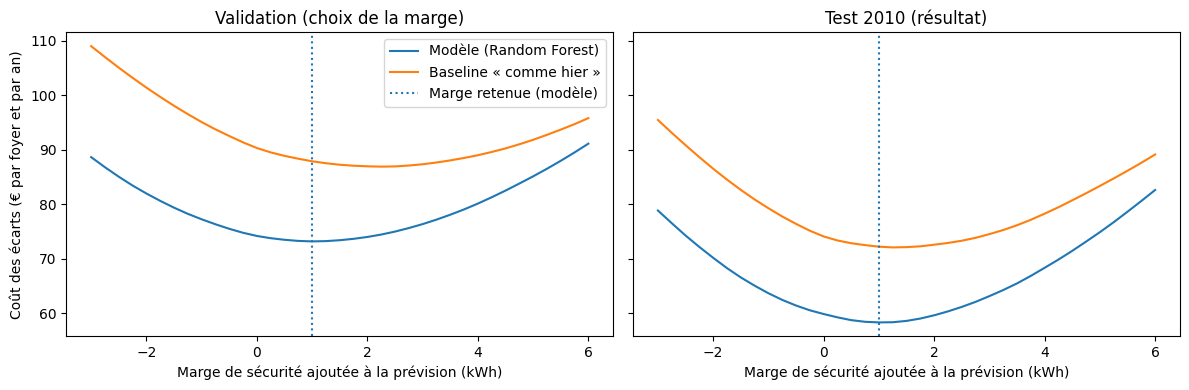

                          Marge (kWh)  Coût test (€/foyer/an)
Baseline, sans marge             0.00                   74.10
Baseline, marge optimale         2.25                   72.91
Modèle, sans marge               0.00                   59.86
Modèle, marge optimale           1.00                   58.32

Gain par foyer et par an : 14.24 € sans marge | 14.59 € avec marge optimale pour chacun


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (titre, y, pm, pb, echelle) in zip(axes, [
        ("Validation (choix de la marge)", y_val, p_mod_val, p_base_val, 365 / len(y_val)),
        ("Test 2010 (résultat)", y_test, p_mod_test, p_base_test, FACTEUR_AN)]):
    ax.plot(GRILLE, courbe_cout(y, pm, C_UNDER, C_OVER, echelle), label="Modèle (Random Forest)")
    ax.plot(GRILLE, courbe_cout(y, pb, C_UNDER, C_OVER, echelle), label="Baseline « comme hier »")
    ax.axvline(central["marge_mod"], color="tab:blue", linestyle=":", label="Marge retenue (modèle)")
    ax.set_title(titre); ax.set_xlabel("Marge de sécurité ajoutée à la prévision (kWh)")
axes[0].set_ylabel("Coût des écarts (€ par foyer et par an)")
axes[0].legend(); plt.tight_layout(); plt.show()

resume = pd.DataFrame({
    "Marge (kWh)": [0.0, central["marge_base"], 0.0, central["marge_mod"]],
    "Coût test (€/foyer/an)": [central["cout0_base"], central["coutopt_base"], central["cout0_mod"], central["coutopt_mod"]]},
    index=["Baseline, sans marge", "Baseline, marge optimale", "Modèle, sans marge", "Modèle, marge optimale"]).round(2)
print(resume)
print(f"\nGain par foyer et par an : {central['gain0']:.2f} € sans marge | {central['gainopt']:.2f} € avec marge optimale pour chacun")

**Interprétation.** La marge de sécurité qui minimise le coût sur la validation est de +1,00 kWh pour le modèle, très proche de la valeur théorique (+1,04 kWh, quantile 0,625 = 0,05 / (0,05 + 0,03) de la distribution des erreurs) : le calcul empirique et la théorie concordent. La baseline demande une marge plus grande (+2,25 kWh) parce que ses erreurs sont plus dispersées.

Le gain apporté par la marge est modeste. Pour le modèle, le coût passe de 59,86 à 58,32 € par foyer et par an sur le test (−2,6 %) ; pour la baseline, de 74,10 à 72,91 €. Les courbes sont plates autour de l'optimum : une marge entre 0 et 2 kWh donne des coûts voisins (58,32 à 59,63 € sur le test), alors qu'une marge de 3 kWh dégrade nettement le résultat (63,15 €). Le coût est plus élevé sur la validation (environ 73 € à la marge optimale) que sur le test (environ 58 €), ce qui est cohérent avec les périodes plus perturbées de 2007-2008 constatées dans le notebook 02.

Avec une marge optimale pour chacun (comparaison équitable), le gain par foyer et par an est de **14,59 €**, contre 14,24 € sans marge : la marge profite un peu plus au modèle qu'à la baseline. C'est ce chiffre de 14,59 € qui sert au calcul du ROI.

## 4 · ROI, scénarios et sensibilité (axe 7)
**Formules** (feuille de consignes) :
- Gain annuel = coût sans modèle − coût avec modèle
- ROI (%) = (gain annuel − coût du projet) / coût du projet × 100
- Délai de retour (mois) = coût du projet / (gain annuel / 12)
- Coût du projet = développement + déploiement + exploitation (1re année)

**Passage du foyer au parc :** gain du parc = `N` × `τ` × gain d'un foyer. Le gain d'un foyer est celui de la section 3, avec la marge optimale appliquée à la baseline **et** au modèle (comparaison équitable, donc plus prudente que sans marge).

**Trois scénarios** (valeurs dans la cellule de la section 1) :
- **pessimiste** : parc réduit, fort foisonnement, écarts peu coûteux ;
- **central** : valeurs de référence ;
- **optimiste** : grand parc, foisonnement faible, écarts plus coûteux.

In [8]:
def roi_scenario(N, tau, c_under, c_over):
    ev = evaluer(c_under, c_over)
    cout_sans = N * tau * ev["coutopt_base"]
    cout_avec = N * tau * ev["coutopt_mod"]
    gain = cout_sans - cout_avec
    return {"Foyers N": N, "Foisonnement τ": tau, "C_UNDER (€/kWh)": c_under, "C_OVER (€/kWh)": c_over,
            "Gain par foyer (€/an)": ev["gainopt"],
            "Coût sans modèle (€/an)": cout_sans, "Coût avec modèle (€/an)": cout_avec,
            "Gain annuel (€)": gain,
            "ROI an 1 (%)": (gain - COUT_PROJET) / COUT_PROJET * 100,
            "Retour (mois)": COUT_PROJET / (gain / 12) if gain > 0 else np.inf}

res_scen = pd.DataFrame({nom: roi_scenario(**p) for nom, p in SCENARIOS.items()}).T
affichage = res_scen.copy()
for col in ["Coût sans modèle (€/an)", "Coût avec modèle (€/an)", "Gain annuel (€)"]:
    affichage[col] = affichage[col].map(lambda v: f"{v:,.0f}".replace(",", " "))
affichage["Foyers N"] = affichage["Foyers N"].map(lambda v: f"{int(v):,}".replace(",", " "))
affichage["Gain par foyer (€/an)"] = affichage["Gain par foyer (€/an)"].astype(float).round(2)
affichage["ROI an 1 (%)"] = affichage["ROI an 1 (%)"].astype(float).round(0)
affichage["Retour (mois)"] = affichage["Retour (mois)"].astype(float).round(1)
print(f"Coût du projet (1re année) : {COUT_PROJET:,.0f} €".replace(",", " "))
affichage

Coût du projet (1re année) : 47 000 €


,Foyers N,Foisonnement τ,C_UNDER (€/kWh),C_OVER (€/kWh),Gain par foyer (€/an),Coût sans modèle (€/an),Coût avec modèle (€/an),Gain annuel (€),ROI an 1 (%),Retour (mois)
Pessimiste,20 000,0.1,0.03,0.02,8.73,91 634,74 173,17 461,-63.0,32.3
Central,50 000,0.2,0.05,0.03,14.59,729 099,583 192,145 907,210.0,3.9
Optimiste,100 000,0.4,0.07,0.04,20.19,3 985 176,3 177 529,807 647,1618.0,0.7


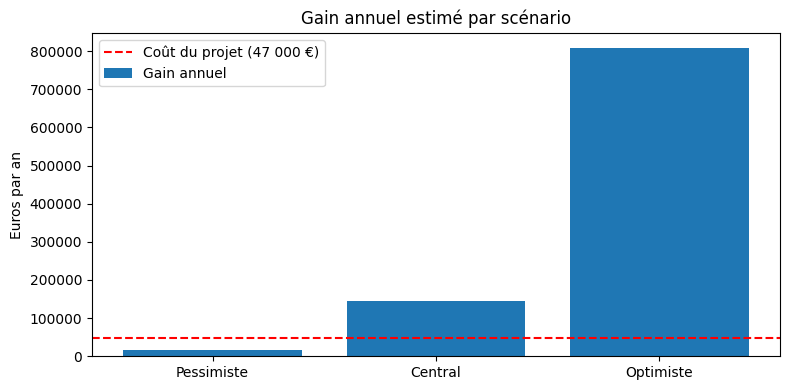

In [9]:
# Gain annuel et coût du projet par scénario
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(res_scen.index, res_scen["Gain annuel (€)"].astype(float), label="Gain annuel")
ax.axhline(COUT_PROJET, color="red", linestyle="--", label=f"Coût du projet ({COUT_PROJET:,.0f} €)".replace(",", " "))
ax.set_title("Gain annuel estimé par scénario"); ax.set_ylabel("Euros par an"); ax.legend()
plt.tight_layout(); plt.show()

**Interprétation.** Le gain par foyer est de 14,59 € par an dans le scénario central (8,73 € dans le scénario pessimiste, où les écarts sont moins coûteux). À l'échelle du parc, avec un coût de projet de 47 000 € :
- **scénario pessimiste** (20 000 foyers, τ = 0,10) : gain annuel de 17 461 €, **ROI de −63 %** et retour en 32 mois, donc un projet non rentable la première année ;
- **scénario central** (50 000 foyers, τ = 0,20) : coût des écarts de 729 099 € par an sans modèle et de 583 192 € avec, soit un gain annuel de 145 907 €, un **ROI de 210 %** et un retour en 3,9 mois ;
- **scénario optimiste** (100 000 foyers, τ = 0,40, écarts plus coûteux) : gain annuel proche de 800 000 €, soit un ROI supérieur à 1 500 %. Ce chiffre est spectaculaire et ne doit pas être présenté comme une certitude : il repose sur trois hypothèses favorables réunies.

Les trois scénarios font varier ensemble la taille du parc, le foisonnement et le prix des écarts. L'écart entre −63 % et plus de 1 500 % montre que le ROI est très sensible aux hypothèses, ce qu'analyse la section suivante. Seuls les scénarios central et optimiste dépassent le coût du projet (graphique).

### Analyse de sensibilité
Un ROI n'a de sens que s'il est accompagné de ce dont il dépend. Trois analyses :
1. **Grille taille du parc × foisonnement**, aux coûts d'écart centraux : où le projet devient-il rentable ?
2. **Seuil de rentabilité** : combien de « foyers équivalents » (`N` × `τ`) faut-il pour couvrir le coût du projet ?
3. **Coût des écarts** : que devient le ROI central si le prix des écarts est deux fois plus bas ou deux fois plus haut ?

In [10]:
gain_foyer = central["gainopt"]                      # € par foyer et par an, aux coûts centraux

# 1. Grille N x tau : ROI de la 1re année (%)
Ns = [5_000, 10_000, 20_000, 50_000, 100_000, 200_000]
taus = [0.05, 0.10, 0.20, 0.40, 0.60, 1.00]
grille_roi = pd.DataFrame([[(n * t * gain_foyer - COUT_PROJET) / COUT_PROJET * 100 for t in taus] for n in Ns],
                          index=[f"{n:,}".replace(",", " ") for n in Ns], columns=[f"τ = {t}" for t in taus])
grille_roi.index.name = "Foyers N"
print("ROI de la 1re année (%), aux coûts d'écart centraux :")
print(grille_roi.round(0).astype(int))

# 2. Seuil de rentabilité
eq = COUT_PROJET / gain_foyer
print(f"\nSeuil de rentabilité : N x τ = {eq:,.0f} foyers équivalents".replace(",", " "))
for t in (0.1, 0.2, 0.4, 1.0):
    print(f"   avec τ = {t:<4} il faut au moins {eq / t:,.0f} foyers".replace(",", " "))

# 3. Sensibilité au coût des écarts (scénario central)
N_c, tau_c = SCENARIOS["Central"]["N"], SCENARIOS["Central"]["tau"]
lignes = []
for f in (0.5, 1.0, 2.0):
    r = roi_scenario(N_c, tau_c, f * C_UNDER, f * C_OVER)
    lignes.append({"Coût des écarts": f"x {f}", "C_UNDER": f * C_UNDER, "C_OVER": f * C_OVER,
                   "Gain annuel (€)": round(r["Gain annuel (€)"]), "ROI an 1 (%)": round(r["ROI an 1 (%)"])})
print("\nSensibilité au coût des écarts (scénario central) :")
pd.DataFrame(lignes).set_index("Coût des écarts")

ROI de la 1re année (%), aux coûts d'écart centraux :
          τ = 0.05  τ = 0.1  τ = 0.2  τ = 0.4  τ = 0.6  τ = 1.0
Foyers N                                                       
5 000          -92      -84      -69      -38       -7       55
10 000         -84      -69      -38       24       86      210
20 000         -69      -38       24      148      273      521
50 000         -22       55      210      521      831     1452
100 000         55      210      521     1142     1763     3004
200 000        210      521     1142     2384     3625     6109

Seuil de rentabilité : N x τ = 3 221 foyers équivalents
   avec τ = 0.1  il faut au moins 32 212 foyers
   avec τ = 0.2  il faut au moins 16 106 foyers
   avec τ = 0.4  il faut au moins 8 053 foyers
   avec τ = 1.0  il faut au moins 3 221 foyers

Sensibilité au coût des écarts (scénario central) :


,C_UNDER,C_OVER,Gain annuel (€),ROI an 1 (%)
Coût des écarts,,,,
x 0.5,0.025,0.015,72954,55
x 1.0,0.050,0.030,145907,210
x 2.0,0.100,0.060,291815,521


### Contrôle de cohérence : calibrage du foisonnement τ
Le paramètre τ est le plus fragile du calcul. Nous pouvons au moins vérifier son **ordre de grandeur** avec le coût moyen réel des écarts publié (0,73 €/MWh en 2025, source secondaire). Si un foyer comme le nôtre consomme `MWh_an` MWh par an, le coût moyen réel des écarts par foyer est de 0,73 × `MWh_an` € par an. En le comparant au coût du foyer sans modèle (section 3), on obtient le τ qui rend notre calcul compatible avec la réalité observée.

**Limite :** le coût réel des écarts correspond à des fournisseurs qui disposent déjà de méthodes de prévision bien meilleures que « comme hier » ; le τ ainsi calibré est donc plutôt un **plancher**.

In [11]:
MWH_AN = float(feat[CIBLE].mean()) * 365 / 1000             # consommation annuelle du foyer étudié (MWh)
PRE_COUT_REEL = 0.73                                         # €/MWh, coût moyen des écarts en 2025 (source secondaire)
cout_ref_foyer = PRE_COUT_REEL * MWH_AN
tau_cal = cout_ref_foyer / central["coutopt_base"]

print(f"Consommation annuelle du foyer étudié : {MWH_AN:.1f} MWh")
print(f"Coût réel moyen des écarts rapporté à ce foyer : {PRE_COUT_REEL} x {MWH_AN:.1f} = {cout_ref_foyer:.1f} € par an")
print(f"Coût du foyer sans modèle (marge optimale)      : {central['coutopt_base']:.1f} € par an")
print(f"=> foisonnement calibré τ ≈ {tau_cal:.2f}  (scénarios retenus : 0,10 / 0,20 / 0,40)")

Consommation annuelle du foyer étudié : 9.6 MWh
Coût réel moyen des écarts rapporté à ce foyer : 0.73 x 9.6 = 7.0 € par an
Coût du foyer sans modèle (marge optimale)      : 72.9 € par an
=> foisonnement calibré τ ≈ 0.10  (scénarios retenus : 0,10 / 0,20 / 0,40)


**Interprétation.** *Seuil de rentabilité.* Le coût du projet est couvert dès que N × τ atteint **3 221 foyers équivalents** (47 000 € divisés par 14,59 € par foyer). Avec τ = 0,10 il faut au moins 32 212 foyers, avec τ = 0,20 il en faut 16 106, avec τ = 0,40 il en faut 8 053 ; si les erreurs de tous les foyers étaient parfaitement corrélées (τ = 1), 3 221 foyers suffiraient.

*Grille.* Pour 50 000 foyers, le ROI est de −22 % si τ = 0,05, de +55 % si τ = 0,10 et de +210 % si τ = 0,20 ; pour un parc de 5 000 foyers, il n'est positif que si τ = 1. Le couple taille du parc et foisonnement décide donc du résultat bien plus que le prix des écarts : dans le scénario central, le ROI reste positif quand le prix des écarts est divisé par deux (+55 %) et il est de +210 % au prix de référence et de +521 % au double.

*Calibrage de τ.* Le foyer étudié consomme 9,6 MWh par an. Au coût réel moyen des écarts (0,73 €/MWh, source secondaire), cela représente environ 7,0 € par an, à comparer aux 72,9 € par an de notre foyer sans modèle (marge optimale) : le foisonnement compatible avec ce coût réel est d'environ **τ ≈ 0,10**, soit celui de notre scénario pessimiste. C'est un plancher (les fournisseurs réels prévoient mieux que « comme hier »), mais il montre que le scénario central (τ = 0,20) est deux fois plus favorable que ce que le coût réel des écarts suggère. À τ = 0,10, le projet n'est rentable qu'à partir de 32 212 foyers (ROI de +55 % pour 50 000 foyers).

L'hypothèse critique n'est donc pas le prix du kWh d'écart mais le foisonnement τ : c'est elle qu'un pilote doit mesurer en priorité.

## 5 · Registre de risques (axe 9)
Risques propres à ce projet, avec une mesure de réduction pour chacun. Les chiffres cités viennent des notebooks 01 et 02.

| Catégorie | Risque | Probabilité | Impact | Mesure de réduction |
|---|---|---|---|---|
| Technique | **Représentativité** : le modèle est entraîné sur un seul foyer (2006-2010) et ne représente pas un parc actuel | Élevée | Élevé | Pilote sur un échantillon de foyers actuels ; réentraînement sur les données du parc avant tout déploiement |
| Technique | **Ruptures brutales** (départs, retours, visiteurs) : les 8 plus grosses erreurs de validation (22 à 30 kWh) sont des ruptures, et les journées atypiques sont deux fois plus mal prévues | Élevée | Moyen | Marge de sécurité calibrée (section 3), intervalle d'erreur à 90 %, ajout du calendrier de vacances connu à l'avance |
| Technique | **Variables absentes** : pas de météo (le chauffage explique l'hiver à 35 kWh/jour) ni de calendrier de présence | Moyenne | Moyen | Intégrer la température prévue et les jours fériés (connus à l'avance) dans une version suivante |
| Technique | **Dérive des données** : nouveaux équipements, pompe à chaleur, télétravail ; le modèle vieillit | Moyenne | Élevé | Suivi mensuel de la MAE face à la baseline ; réentraînement trimestriel ; repli sur la baseline si le gain disparaît |
| Technique | **Trous de collecte** : jusqu'à 5 jours consécutifs sans données (25 jours incomplets sur 1 442) | Moyenne | Moyen | Règle de repli (baseline « semaine dernière ») et indicateur de qualité des données |
| Métier | **Hypothèse de foisonnement τ** : le gain sur un parc dépend de la compensation des erreurs entre foyers, impossible à mesurer avec un seul foyer | Élevée | Élevé | Pilote de 3 mois pour mesurer l'erreur réelle du parc agrégé ; suivi de la MAE agrégée |
| Métier | **Coût réel des écarts différent des hypothèses** : `C_UNDER` et `C_OVER` sont des hypothèses | Moyenne | Élevé | Validation avec l'équipe d'achat d'énergie sur les prix de règlement réels ; analyse de sensibilité (section 4) |
| Métier | **Adoption** : le responsable des achats ne fait pas confiance à une prévision peu expliquée | Moyenne | Moyen | Importance des variables documentée ; modèle linéaire en repli (MAE de validation 5,32 contre 5,23, donc proche) |
| Éthique et réglementaire | **Données personnelles (RGPD)** : une consommation fine révèle les habitudes et la présence au domicile | Élevée | Élevé | Travailler au pas journalier, minimiser et pseudonymiser les données, base légale et consentement, pas de données à la minute hors besoin |
| Environnemental | **Coût énergétique du calcul** : une forêt de 200 arbres sur environ 1 100 lignes, quelques secondes de calcul | Faible | Faible | Privilégier des modèles simples ; suivre la consommation de calcul si le parc grandit |

## 6 · Recommandation

**Recommandation.** Nous proposons de remplacer la prévision « comme hier » par un modèle de prévision de la consommation du lendemain (Random Forest), en **passant par un pilote de 3 mois avant tout déploiement**.

- **Ce que montrent les résultats.** Sur des données jamais vues (2010), le modèle réduit l'erreur de 17,2 % (4,22 contre 5,10 kWh par jour et par foyer) et le coût des écarts de 19,2 %, soit 14,59 € par foyer et par an avec une marge de sécurité de +1 kWh.
- **Valeur à l'échelle d'un parc.** Sous nos hypothèses, le scénario central donne un gain d'environ 146 000 € par an pour un coût de projet de 47 000 € (ROI de 210 %, retour en 4 mois). Le scénario pessimiste est en revanche négatif (ROI de −63 %, retour en 32 mois), et le projet n'est rentable qu'à partir de **3 221 foyers équivalents** (N × τ).
- **Pourquoi un pilote.** Le résultat dépend surtout de deux éléments que nos données ne permettent pas de mesurer : le foisonnement τ (le calibrage sur le coût réel des écarts suggère environ 0,10, soit deux fois moins que dans le scénario central) et la représentativité du foyer étudié. Le pilote doit mesurer l'erreur réelle du parc agrégé, le coût réel des écarts et la performance du modèle sur des foyers actuels.
- **Critère de décision.** Déployer si le pilote montre un gain au moins égal au seuil de rentabilité sur le parc visé ; sinon, conserver la baseline et revoir le périmètre.
- **Limites à rappeler.** Un seul foyer (2006-2010) ; des ruptures brutales mal prévues (les journées atypiques sont deux fois plus mal prévues) ; des coûts d'écart et des coûts de projet posés comme hypothèses.

In [12]:
res_scen.to_csv(os.path.join(DATA_DIR, "resultats_roi.csv"), index_label="scenario")
grille_roi.to_csv(os.path.join(DATA_DIR, "sensibilite_roi.csv"))
print("Fichiers enregistrés :", ["resultats_roi.csv", "sensibilite_roi.csv"])

Fichiers enregistrés : ['resultats_roi.csv', 'sensibilite_roi.csv']
